products_attrs.update({
"I":'8-bit image color values of the timestack. Three dimensions: time, spatial axis, color band, where the colors are RGB--R(ed) color band equals 0, G(reen) color band equals 1, and B(blue) color band equals 2. The horizontal axis of the image is the spatial axis. The different crs_ mappings represent the same coordinates in UTM, local, and longitude/latitude.',
"shoreline_elevation"                
"Ri": "pixel coordinate of wave runup line as found by the segformer model.
"runup_val":"Runup value used to extract runup from softmax score: 
“rundown_val”:"Rundown value used to extract rundown from softmax score."
"U_transect": "pixel coordinate along the horizontal axis of the image where timestack was sampled"
"V_transect": "pixel coordinate along the vertical axis of the image where timestack was sampled",
"T": "YYYY-MM-DD HH:mm:SS+00:00", "Times that pixels were sampled to create the timestack. The dimension length is the number of samples in the timestack. Each sample has a time value represented as a datetime.",
"Eastings":f'Eastings coordinates of data in the timestack pixels projected onto the beach surface at {self.site}. Described using UTM Zone {utmzone} Easting in meters.',                   
"Northings": f'Northings coordinates of data in the timestack pixels projected onto the beach surface at {self.site}. Described using UTM Zone {utmzone} Northing in meters.',
"Elevation":f'Elevation (z-value) in {verticalDatum} of timestack pixels projected onto the beach surface at {self.site}.',
"localX":"long_name": "description":" Local cross-shore coordinates in meters of rectified image. Rotated based on shorenormal angle and origin. "
"localY":" Local along-shore coordinates in meters of rectified image. Rotated based on shorenormal angle and origin. ",
"Hrunup_utm": "Horizontal coordinates of wave runup as converted from U,V coordinates to Eastings, Northings from EO/IO.",
"Hrunup_local":"Horizontal coordinates of wave runup in a local coordinate system. Rotated based on shorenormal angle and origin.",
"TWL":"Vertical elevation of total water level.",         
Zrunup":"Vertical elevation of wave runup (total water level - TWL_tideWindSetup).",
                             


TWL_attrs = 
"2exceedence_peaksVar":"2 percent exceedence value for twl peaks",
"2exceedence_notpeaksVar": "2 percent exceedence value for twl timeseries",
"setup": "wave setup"
"TpeakVar":"runup (or twl) timeseries peak period"
"TmeanVar": "runup (or twl) timeseries mean period"
 "SsigVar": "significant swash",
"Ssig_SSVar":"significant swash in sea-swell (SS) band" f"Between {freqLimits[0]} Hz and {freqLimits[1]} Hz."
 "Ssig_IGVar": "significant swash in infragravity (IG) band", f"Between {freqLimits[1]} Hz and {freqLimits[2]} Hz."
"SpectrumVar": "runup (or twl) spectral density array",
"FrequencyVar": "runup (or twl) frequency array",
"betaS2006":"beach slope between +- 2std(twl timeseries)", "as defined in Stockdon et al. (2006)"
"betaminmax":"beach slope between +max(twl timeseries)/-min(twl timesereis)",
"twl": "TWL Forecast", f"converted from LMSL to NAVD88m with {vdatum_offset}."
"twl05":"TWL Forecast 5% confidence interval",
"twl95": "TWL Forecast 95% confidence interval",
 "twl_setup": "TWL Forecast setup",
 "Twl_runup": TWL Forecast runup",
"twl_runup05": "TWL Forecast runup 5% CI"
 "twl_runup95":"TWL Forecast 95% CI"
"twl_tide":"TWL Forecast tide + wind setup : used for tide",
"twl_swash": "TWL Forecast swash",
 “twl_incSwash": "TWL Forecast incident swash",
"twl_igSwash":"TWL Forecast infragravity swash",
  "twl_hs": "TWL Forecast Ho",  
 "twl_pp":”TWL Forecast Tp",


In [ ]:
import netCDF4 as nc
mynetcdf = nc.Dataset('D:/cvolpano/DATA/Shorescan/DATA/DATA/netcdf/1740002400.Wed.Feb.19_22_00_00.GMT.2025.CACO04.c1.ras_transect20.nc')
# print(mynetcdf)
#print(mynetcdf.variables.keys)
value = mynetcdf['Zrunup']  # Returns 42.5
print(value)

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import r2_score

# Folder containing runup NetCDFs
nc_dir = Path("D:/cvolpano/DATA/Shorescan/DATA/DATA/netcdf")

calc_2perc = []
cirn_2perc = []
filenames = []

for ncfile in sorted(nc_dir.glob("*.nc")):

    try:
        ds = xr.open_dataset(ncfile)
        
        # TWL timeseries for this burst
        twl_viewer = ds["twl"]   

        # Empirical 2% exceedance
        twl_viewer_2pct = np.percentile(twl_viewer, 98)

        # CIRN value
        twl_ss = ds["TWL"].values
        twl_ss_2pct = np.percentile(twl_ss, 98)

        if np.isfinite(twl_viewer_2pct) and np.isfinite(twl_ss_2pct):
            calc_2perc.append(twl_viewer_2pct)
            cirn_2perc.append(twl_ss_2pct)
            filenames.append(ncfile.name)

        ds.close()

    except Exception as e:
        print(f"Skipping {ncfile.name}: {e}")

calc_2perc = np.array(calc_2perc)
cirn_2perc = np.array(cirn_2perc)

# Statistics
r2 = r2_score(cirn_2perc, calc_2perc)
bias = np.mean(calc_2perc - cirn_2perc)
rmse = np.sqrt(np.mean((calc_2perc - cirn_2perc)**2))

# Plot
plt.figure(figsize=(8,8))

plt.scatter(
    cirn_2perc,
    calc_2perc,
    alpha=0.7
)

mn = min(cirn_2perc.min(), calc_2perc.min())
mx = max(cirn_2perc.max(), calc_2perc.max())

plt.plot(
    [mn, mx],
    [mn, mx],
    'k--',
    lw=2,
    label='1:1'
)

plt.xlabel('Shorescan 98th Percentile of TWL (m)')
plt.ylabel('TWL Viewer 98th Percentile of TWL (m)')
plt.title(f'N = {len(calc_2perc)} bursts')

plt.text(
    0.05,
    0.95,
    f'R² = {r2:.3f}\nBias = {bias:.3f} m\nRMSE = {rmse:.3f} m',
    transform=plt.gca().transAxes,
    va='top'
)

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import glob
import os
import re
import matplotlib.pyplot as plt 
import numpy as np
import pandas as pd
import xarray as xr


dirpath = 'D:/cvolpano/DATA/Shorescan/DATA/DATA/netcdf'
records = []
os.chdir(dirpath)

for file in glob.glob("*.nc"):
    fname = os.path.basename(file)
    
    if not re.search(r'transect\d+', fname):
        print(f"Skipping {fname} as it does not match the expected pattern.")
        continue
    transect = int(re.search(r'transect(\d+)', fname).group(1))
    camera = re.search(r'\.(c\d)\.', fname).group(1)
    
    for ti, ri in zip(t, zrunup):
        records.append({
            "time": ds["T_dim"].values,
            "transect": transect,
            "camera": camera,
            "tide": ds["twl_tide"].values,
            "twl_runup": ds['twl_runup'].values,
            "twl": ds["twl"].values, # viewer TWL timeseries
            "Hs":  ds["twl_hs"].values,
            "twl05": ds["twl05"].values,
            "twl95": ds["twl95"].values,
            "beta06": ds['TWLstats_betaS2006'].values,
            "TWL": ds["TWL"].values, #shorescan TWL timeseries
            "Zrunup": ds["Zrunup"].values, # TWL - tide
        })

        


df = pd.DataFrame(records)
print(df.head())




                                                time  transect camera   tide  \
0  [2025-02-09T16:00:00.000000000, 2025-02-09T16:...        40     c1  0.918   
1  [2025-02-09T16:00:00.000000000, 2025-02-09T16:...        40     c1  0.918   
2  [2025-02-09T16:00:00.000000000, 2025-02-09T16:...        40     c1  0.918   
3  [2025-02-09T16:00:00.000000000, 2025-02-09T16:...        40     c1  0.918   
4  [2025-02-09T16:00:00.000000000, 2025-02-09T16:...        40     c1  0.918   

  twl_runup    twl    Hs               twl05               twl95  \
0      0.41  1.178  0.88  1.0579999999999998  1.2979999999999998   
1      0.41  1.178  0.88  1.0579999999999998  1.2979999999999998   
2      0.41  1.178  0.88  1.0579999999999998  1.2979999999999998   
3      0.41  1.178  0.88  1.0579999999999998  1.2979999999999998   
4      0.41  1.178  0.88  1.0579999999999998  1.2979999999999998   

                 beta06                                                TWL  \
0  0.023831454033522614  [-0.525

ValueError: setting an array element with a sequence.

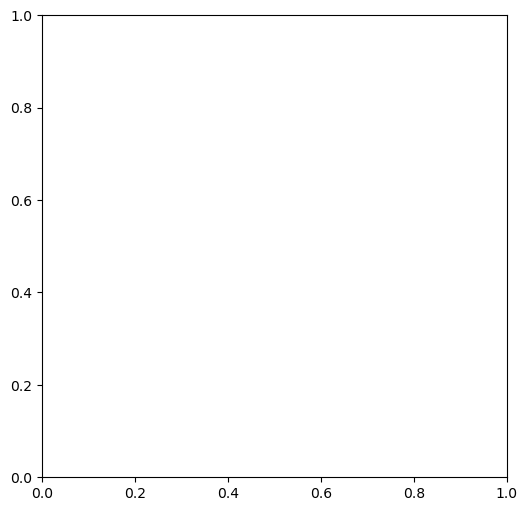

In [29]:
'''
plt.figure(figsize=(12,6))
ds["TWL"].plot(
    x="T_dim",
)
'''
df["twl_num"] = df["twl"].astype(float)
# df["TWL_clean"]= df["TWL"].apply(lambda x: np.max(x) if isinstance(x, (list, tuple, np.ndarray)) else x)

# print(df["TWL_clean"])
# df["TWL_num"] = df["Hs"].astype(float)
# 2. Setup the empty figure window first
df["Zrunup_av"] = df["Zrunup"].apply(lambda x: np.median(x) if isinstance(x, (list, tuple, np.ndarray)) else x)

ax = df.plot(figsize=(6,6), kind = "scatter", x="twl_num", y="TWL", color = "teal",label = None)
ax.set_xlabel("TWL Viewer")
ax.set_ylabel("Total Water Level (m)")
plt.show()

'''ax = df.plot(figsize=(12,6), kind = "scatter", x="time", y="twl_num", color = "teal",label = "TWL Viewer")
df.plot(kind = "scatter", x="time", y="TWL_clean", color = "coral", label = "Shorescan", ax=ax)
ax.set_xlabel("Time")
ax.set_ylabel("Total Water Level (m)")
plt.show()'''

# 3. Plot using the NEW numeric column "twl_num"



In [ ]:

print(type(records[0]["Zrunup"]))
print(records[0]["Zrunup"])
print(t[-1000])

In [ ]:
df.to_csv("Shorescan_variables_01232025-02192025.csv")

In [ ]:
print(df[["time", "Zrunup"]].head())
print(df["time"])



In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1,figsize = (10,6))
cmap_plot = ax.scatter(df["twl_runup"],df["Zrunup"],
           c = df["Hs"],
           s = 20,
           edgecolors = "black",
           alpha = 1,
           linewidths = 0.15,
            )
ax.set_xlabel("TWL&CC TWL Runup (m)")
ax.set_ylabel("Shorescan TWL Runup (m)")
cbar = plt.colorbar(cmap_plot, ax=ax, orientation='vertical')
cbar.set_label('Significant Wave Height (m)', fontsize=12)  # Label
# Get current axis limits
xmin, xmax = plt.xlim()
ymin, ymax = plt.ylim()

# Determine the range for the 1:1 line
line_min = min(xmin, ymin)
line_max = max(xmax, ymax)

plt.plot([line_min, line_max], [line_min, line_max],
         color='black', linestyle='--', linewidth=1.5, label='1:1 Line')
plt.xlim(line_min, line_max)
plt.ylim(line_min, line_max)


In [ ]:
import matplotlib.pyplot as plt

transects = sorted(df["transect"].unique())


fig, axes = plt.subplots(
    len(transects),
    1,
    figsize=(16, 10),
    sharex=True,
    constrained_layout=True
)

for ax, tr in zip(axes, transects):
    
    c1 = df[
        (df["transect"] == tr) &
        (df["camera"] == "c1")
    ]

    c2 = df[
        (df["transect"] == tr) &
        (df["camera"] == "c2")
    ]
    # Sort by time first
    c1 = c1.sort_values("time")
    c2 = c2.sort_values("time")

    ax.scatter(
        c1["time"],
        c1["Zrunup"][0],
        s=20,
        edgecolors = "black",
        alpha=0.4,
        linewidths=0.15,
        label="c1"
    )
    ax.plot(
        c1["time"],
        c1["beta06"],
        linewidth=1,
        alpha=0.8,
        label="_nolegend_"
    )   

    ax.scatter(
        c2["time"],
        c2["Zrunup"][0],
        s=20,
        edgecolors = "black",
        linewidths=0.15,
        alpha=0.4,
        label="c2"
    )

    ax.plot(
        c2["time"],
        c2["beta06"],
        linewidth=1,
        alpha=0.8,
        label="_nolegend_"
    )
    ax.set_ylabel(f"T{tr}")

axes[0].legend()
#axes[0].set_title(f"Runup Time Series — {day.date()}")
axes[-1].set_xlabel("Time (UTC)")

plt.show()